# O Impacto Real da Reamostragem (Paradoxo da Acurácia)
Este notebook utiliza uma base real do `scikit-learn` (Dígitos) para provar o impacto das técnicas de balanceamento em um modelo KNN.

**O Problema:** Detectar o dígito '9' (Evento raro: ~10%) no meio de outros números (Fluxo normal: ~90%).

**A Regra de Ouro:** As técnicas de manipulação (`fit_resample`) são aplicadas **apenas no conjunto de treino**. O modelo é sempre avaliado em um conjunto de teste que permaneceu intacto e desbalanceado.

In [16]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Carregar base real e binarizar (Classe 1 = '9', Classe 0 = Outros)
digits = load_digits()
X = digits.data
y = (digits.target == 9).astype(int)

print(f"Distribuição Total:\n0 (Maioria): {sum(y==0)}\n1 (minoritária): {sum(y==1)}")

# Separar Treino e Teste (O Teste é sagrado e não sofre reamostragem)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("\nDados separados com sucesso!")

Distribuição Total:
0 (Maioria): 1617
1 (minoritária): 180

Dados separados com sucesso!


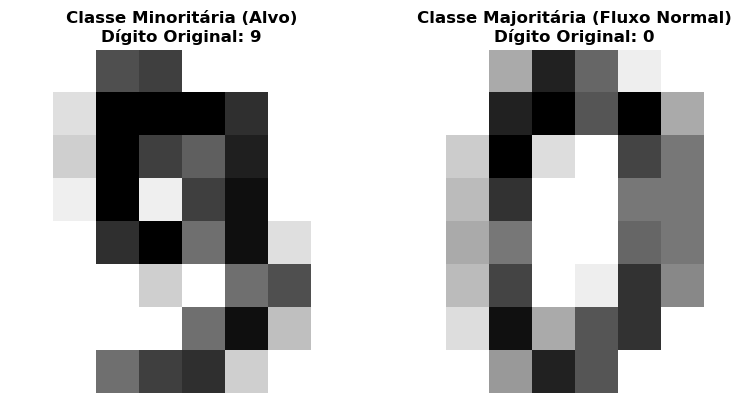

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Encontrar os índices para a plotagem
idx_minoria = np.where(digits.target == 9)[0][0]  # Pega o primeiro '9'
idx_maioria = np.where(digits.target != 9)[0][0]  # Pega o primeiro número diferente de '9' (será o '0')

# Configurar a figura com 2 subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Plotar a imagem da classe minoritária
axes[0].imshow(digits.images[idx_minoria], cmap='gray_r')
axes[0].set_title(f"Classe Minoritária (Alvo)\nDígito Original: {digits.target[idx_minoria]}", fontweight='bold')
axes[0].axis('off')

# Plotar a imagem da classe majoritária
axes[1].imshow(digits.images[idx_maioria], cmap='gray_r')
axes[1].set_title(f"Classe Majoritária (Fluxo Normal)\nDígito Original: {digits.target[idx_maioria]}", fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Treinamento e Avaliação Desagregada
Aqui inicializamos o classificador KNN e testamos as 4 abordagens, monitorando de perto o impacto na **Revocação (Recall)** da classe minoritária.

In [18]:

samplers = {
    'Linha de Base (S/ alterar)': None,
    'Random Undersampling': RandomUnderSampler(random_state=42),
    'Tomek Links (Limpeza)': TomekLinks(),
    'Random Oversampling': RandomOverSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42)
}

results = []

for name, sampler in samplers.items():
    # APLICAR APENAS NO TREINO
    if sampler is None:
        X_res, y_res = X_train, y_train
    else:
        X_res, y_res = sampler.fit_resample(X_train, y_train)
        
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(X_res, y_res)
    
    # TESTAR NO CONJUNTO INTACTO
    y_pred = knn.predict(X_test)
    
    # Coletar Métricas para a Classe Minoritária (1)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    
    results.append({
        'Técnica': name,
        'Tam. Treino': len(y_res),
        'Acurácia Global': f"{acc:.3f}",
        'Recall (min)': f"{rec:.3f}",
        'Precisão (min)': f"{prec:.3f}",
        'F1-Score (min)': f"{f1:.3f}"
    })

# Exibir a tabela final de resultados
df_results = pd.DataFrame(results)
display(df_results)


,Técnica,Tam. Treino,Acurácia Global,Recall (min),Precisão (min),F1-Score (min)
0,Linha de Base (S/ alterar),1257,0.996,0.963,1.000,0.981
1,Random Undersampling,252,0.946,0.963,0.658,0.782
2,Tomek Links (Limpeza),1257,0.996,0.963,1.000,0.981
3,Random Oversampling,2262,0.993,0.981,0.946,0.964
4,SMOTE,2262,0.993,1.000,0.931,0.964
